# Chapitre 6 - Cours 2 : rééquilibrer les partitions

Un cluster ne garde pas la même taille toute sa vie : les données et le débit
grossissent, des machines tombent en panne et sont remplacées. Il faut alors **déplacer**
des données d'un nœud à l'autre : c'est le **rééquilibrage**. Ce notebook couvre la
section *Rebalancing Partitions* : *Strategies for Rebalancing* (*How not to do it: hash
mod N*, *Fixed number of partitions*, *Dynamic partitioning*, *Partitioning
proportionally to nodes*), l'encadré *Consistent Hashing* de la section *Partitioning by
Hash of Key*, et *Operations: Automatic or Manual Rebalancing*.

**Plan.**

1. Ce qu'on attend d'un rééquilibrage, et la borne inférieure du volume à déplacer.
2. Ce qu'il ne faut pas faire : haché modulo le nombre de nœuds.
3. Un nombre fixe de partitions, plus nombreuses que les nœuds.
4. Le partitionnement dynamique : des partitions qui se scindent.
5. Des partitions proportionnelles aux nœuds, et le hachage cohérent.
6. Rééquilibrage automatique ou manuel : le risque de cascade.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Wedge

from ddia import partitioning as P
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")
KEYS = np.arange(200_000)                       # 200 000 clés entières pour toutes les mesures

## 1. Ce qu'on attend d'un rééquilibrage (section *Rebalancing Partitions*)

Trois exigences, quelle que soit la stratégie :

1. **après** le rééquilibrage, la charge (données, lectures, écritures) est de nouveau
   répartie équitablement entre les nœuds ;
2. **pendant** le rééquilibrage, la base continue d'accepter lectures et écritures ;
3. on ne déplace **pas plus de données que nécessaire**, pour que l'opération soit rapide
   et ménage le réseau et les disques.

**La borne inférieure.** Passer de $n$ à $n+1$ nœuds équilibrés impose au nouveau venu de
recevoir $1/(n+1)$ des données ; elles viennent forcément d'ailleurs. Aucune stratégie ne
peut donc déplacer moins de $1/(n+1)$ des clés, et une stratégie **optimale** atteint
exactement cette fraction en ne déplaçant **que vers le nouveau nœud** (aucun échange
entre anciens nœuds). Le diagramme montre ce rééquilibrage idéal pour $n = 3$ : chaque
ancien nœud cède un quart de ses données, soit un douzième du total chacun.

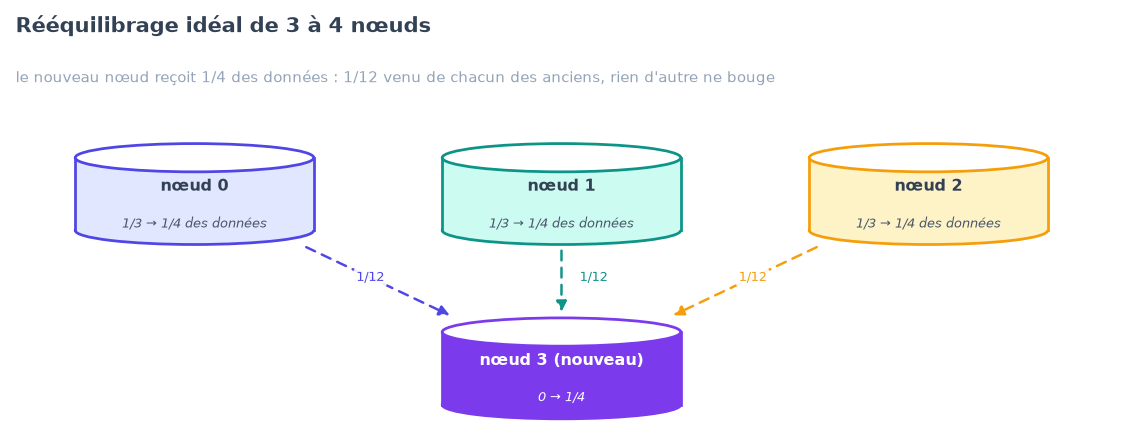

In [2]:
d = Diagram(12, 3.6, title="Rééquilibrage idéal de 3 à 4 nœuds",
            subtitle="le nouveau nœud reçoit 1/4 des données : 1/12 venu de chacun des anciens, rien d'autre ne bouge")
for i, c in enumerate([INDIGO, TEAL, AMBER]):
    d.box(f"n{i}", 2.0 + i * 4.0, 2.55, f"nœud {i}", sub="1/3 → 1/4 des données", color=c, kind="db", w=2.6, h=1.1)
d.box("new", 6.0, 0.65, "nœud 3 (nouveau)", sub="0 → 1/4", color=VIOLET, kind="db", w=2.6, h=1.1, filled=True)
for i, c in enumerate([INDIGO, TEAL, AMBER]):
    d.arrow(f"n{i}", "new", "1/12", color=c, style="dashed", label_pos=0.45, label_offset=(0.35 if i == 1 else 0, 0))
d.show()

Mesurons maintenant chaque stratégie à cette aune : la **fraction de clés déplacées** lors
de l'ajout d'un nœud, comparée à l'optimum $1/(n+1)$.

> **À retenir.** Un bon rééquilibrage rétablit l'équité, ne bloque pas le service et ne
> déplace que le strict nécessaire : au moins $1/(n+1)$ des données quand on passe de $n$
> à $n+1$ nœuds, et rien entre les anciens nœuds.

## 2. Ce qu'il ne faut pas faire : haché modulo N (section *How not to do it: hash mod N*)

La première idée qui vient à l'esprit : nœud $= h(\text{clé}) \bmod N$. Simple, uniforme...
et désastreux au rééquilibrage, car **changer $N$ change le reste de presque toutes les
clés**. La grille ci-dessous montre les hachés 0 à 23 répartis sur 3, 4 puis 5 nœuds ; les
cases cerclées de rose ont changé de nœud par rapport à la ligne du dessus.

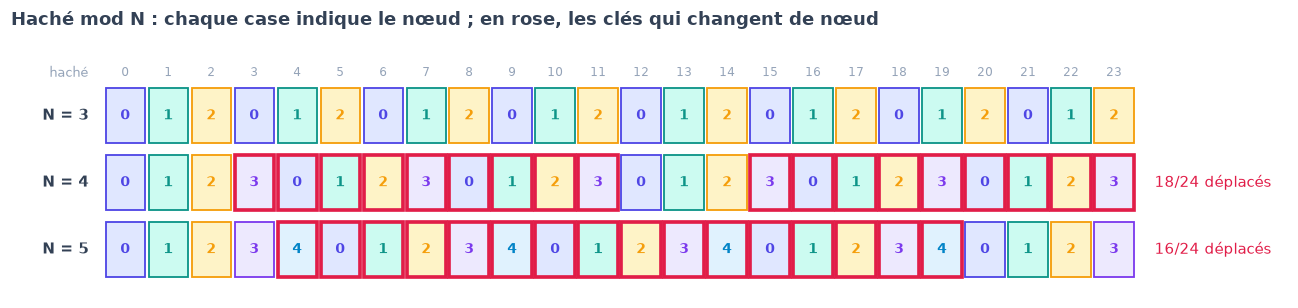

In [3]:
hs = np.arange(24)
fig, ax = plt.subplots(figsize=(12, 2.9))
node_colors = [INDIGO, TEAL, AMBER, VIOLET, SKY]
for r, N in enumerate([3, 4, 5]):
    for h in hs:
        node = h % N
        moved = r > 0 and node != h % (N - 1)
        ax.add_patch(plt.Rectangle((h, -r), 0.92, 0.82, facecolor=LIGHT[node_colors[node]],
                                   edgecolor=ROSE if moved else node_colors[node], lw=2.4 if moved else 1.2))
        ax.text(h + 0.46, -r + 0.41, str(node), ha="center", va="center", fontsize=9,
                color=node_colors[node], fontweight="bold")
    n_moved = sum((h % N) != (h % (N - 1)) for h in hs) if r else 0
    ax.text(-0.4, -r + 0.41, f"N = {N}", ha="right", va="center", fontsize=10, fontweight="bold", color=SLATE)
    if r:
        ax.text(24.4, -r + 0.41, f"{n_moved}/24 déplacés", ha="left", va="center", fontsize=9.5, color=ROSE)
for h in hs:
    ax.text(h + 0.46, 1.05, str(h), ha="center", va="center", fontsize=8, color=GRAY)
ax.text(-0.4, 1.05, "haché", ha="right", va="center", fontsize=8.5, color=GRAY)
ax.set_xlim(-2.2, 27.5); ax.set_ylim(-2.3, 1.4); ax.axis("off")
ax.set_title("Haché mod N : chaque case indique le nœud ; en rose, les clés qui changent de nœud")
plt.tight_layout(); plt.show()

**Pourquoi $N/(N+1)$ ?** Si les hachés sont uniformes, le couple
$(h \bmod N,\ h \bmod (N+1))$ est uniforme sur les $N(N+1)$ couples possibles (théorème
chinois des restes, $N$ et $N+1$ étant premiers entre eux). La clé reste en place si les
deux restes sont égaux : $N$ couples sur $N(N+1)$, soit une probabilité $1/(N+1)$. Elle
**bouge** donc avec probabilité $N/(N+1)$, alors que l'optimum est $1/(N+1)$ : c'est
exactement le contraire de ce qu'on veut. Vérifions par la mesure.

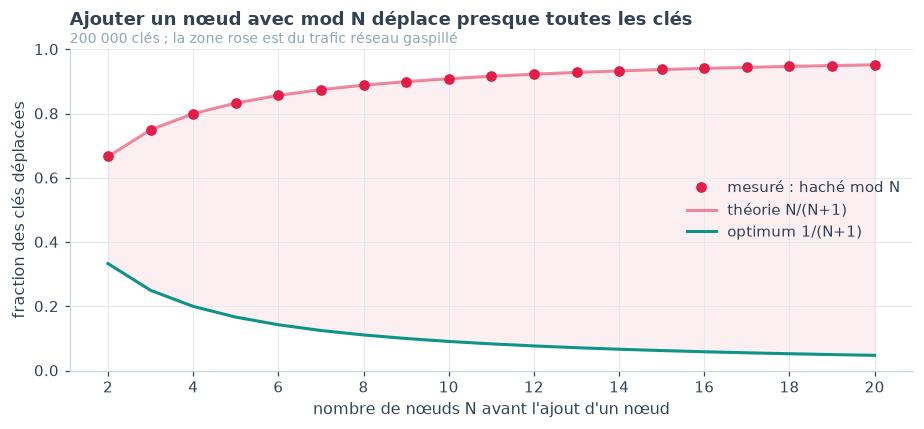

de 10 à 11 nœuds : 90.8% des clés bougent, contre 9.1% au minimum


In [4]:
Ns = np.arange(2, 21)
mod_moved = [P.moved_fraction(P.mod_n_assign(KEYS, N), P.mod_n_assign(KEYS, N + 1)) for N in Ns]
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(Ns, mod_moved, "o", color=ROSE, label="mesuré : haché mod N")
ax.plot(Ns, Ns / (Ns + 1), "-", color=ROSE, alpha=0.5, label="théorie N/(N+1)")
ax.plot(Ns, 1 / (Ns + 1), "-", color=TEAL, label="optimum 1/(N+1)")
ax.fill_between(Ns, 1 / (Ns + 1), Ns / (Ns + 1), color=ROSE, alpha=0.07)
ax.set_xlabel("nombre de nœuds N avant l'ajout d'un nœud"); ax.set_ylabel("fraction des clés déplacées")
ax.set_ylim(0, 1); ax.set_xticks(Ns[::2])
ax.set_title("Ajouter un nœud avec mod N déplace presque toutes les clés")
subtitle(ax, "200 000 clés ; la zone rose est du trafic réseau gaspillé")
ax.legend(loc="center right")
plt.tight_layout(); plt.show()
print(f"de 10 à 11 nœuds : {mod_moved[8]:.1%} des clés bougent, contre {1 / 11:.1%} au minimum")

Passer de 10 à 11 nœuds déplace 91 % des clés, dix fois le nécessaire : sur un cluster de
50 To, cela fait 45 To à transférer au lieu de 4,5.

> **À retenir.** Haché mod N déplace une fraction $N/(N+1)$ des clés à chaque changement de
> taille : il faut découpler « clé → morceau » de « morceau → nœud ».

## 3. Un nombre fixe de partitions (section *Fixed number of partitions*)

**L'idée.** Créer dès le départ **beaucoup plus de partitions que de
nœuds** (par exemple 1 000 pour 10 nœuds) : la clé va dans la partition
$h(\text{clé}) \bmod 1000$, **pour toujours**, et une table séparée dit quel nœud
héberge quel morceau. Ajouter un nœud revient à lui confier quelques morceaux entiers,
pris aux nœuds les plus chargés ; l'affectation des clés aux morceaux ne change jamais.
Riak, Elasticsearch, Couchbase ou Redis Cluster (16 384 *slots*, voir le lab)
fonctionnent ainsi.

Faisons grandir un cluster de 240 morceaux de 3 à 12 nœuds, un nœud à la fois.

In [5]:
cl = P.FixedShardCluster(240, ["n0", "n1", "n2"])
rows = []
prev = cl.owner_names(KEYS)
for k in range(3, 12):
    moved_shards = cl.add_node(f"n{k}")
    cur = cl.owner_names(KEYS)
    rows.append({"nœuds": f"{k} → {k + 1}", "morceaux déplacés": len(moved_shards),
                 "clés déplacées": P.moved_fraction(prev, cur), "optimum 1/(n+1)": 1 / (k + 1),
                 "morceaux par nœud": f"{min(cl.shards_per_node().values())}-{max(cl.shards_per_node().values())}"})
    prev = cur
growth = pd.DataFrame(rows)
growth

,nœuds,morceaux déplacés,clés déplacées,optimum 1/(n+1),morceaux par nœud
0,3 → 4,60,0.250,0.250,60-60
1,4 → 5,48,0.199,0.200,48-48
2,5 → 6,40,0.168,0.167,40-40
3,6 → 7,34,0.141,0.143,34-35
4,7 → 8,30,0.124,0.125,30-30
5,8 → 9,26,0.109,0.111,26-27
6,9 → 10,24,0.100,0.100,24-24
7,10 → 11,21,0.088,0.091,21-22
8,11 → 12,20,0.083,0.083,20-20


Chaque ajout déplace exactement la part optimale (au morceau près) : passer de 3 à 4 nœuds
transfère 60 morceaux sur 240, soit 25 % des clés, et uniquement vers le nouveau nœud.
Le diagramme montre ce premier ajout : chaque ancien nœud cède 20 de ses 80 morceaux.

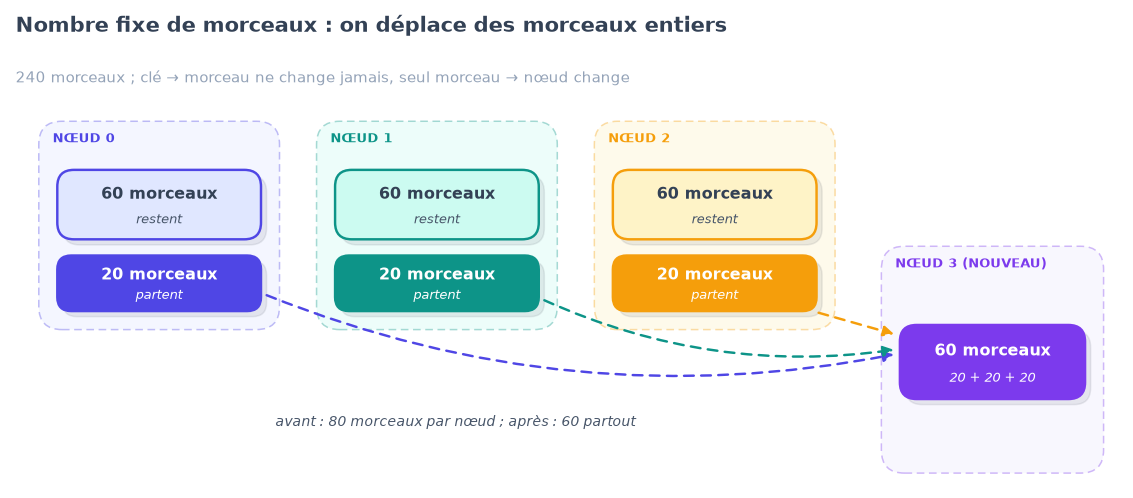

In [6]:
d = Diagram(12, 4.2, title="Nombre fixe de morceaux : on déplace des morceaux entiers",
            subtitle="240 morceaux ; clé → morceau ne change jamais, seul morceau → nœud change")
for i, c in enumerate([INDIGO, TEAL, AMBER]):
    x0 = 0.3 + i * 3.0
    d.group(x0, 1.7, x0 + 2.6, 3.95, f"nœud {i}", color=c)
    d.box(f"keep{i}", x0 + 1.3, 3.05, "60 morceaux", sub="restent", color=c, w=2.2, h=0.75)
    d.box(f"give{i}", x0 + 1.3, 2.2, "20 morceaux", sub="partent", color=c, w=2.2, h=0.6, filled=True)
d.group(9.4, 0.15, 11.8, 2.6, "nœud 3 (nouveau)", color=VIOLET)
d.box("recv", 10.6, 1.35, "60 morceaux", sub="20 + 20 + 20", color=VIOLET, w=2.0, h=0.8, filled=True)
for i, c in enumerate([INDIGO, TEAL, AMBER]):
    d.arrow(f"give{i}", "recv", None, color=c, style="dashed", rad=0.15 if i < 2 else 0.0)
d.note(4.8, 0.7, "avant : 80 morceaux par nœud ; après : 60 partout")
d.show()

**Machines hétérogènes.** Comme on déplace des morceaux et non des clés, rien n'empêche
de donner plus de morceaux aux machines plus puissantes :

In [7]:
het = P.FixedShardCluster(240, ["petit-1", "petit-2", "gros"], weights={"gros": 2.0})
pd.DataFrame({"morceaux": het.shards_per_node(),
              "part des clés": pd.Series(het.owner_names(KEYS)).value_counts(normalize=True)}).T.round(3)

,gros,petit-1,petit-2
morceaux,120.000,60.000,60.000
part des clés,0.501,0.251,0.248


**Combien de morceaux ?** Le nombre est fixé à la création. On le choisit divisible par
beaucoup d'entiers, pour que les morceaux se répartissent **exactement** sur des
clusters de tailles variées (sans exiger, par exemple, une puissance de 2 nœuds).
Comparons quelques candidats : pour combien de tailles de cluster entre 1 et 32 nœuds la
répartition est-elle parfaite, et quel écart reste-t-il sinon ?

In [8]:
cands = [240, 256, 720, 1000, 1024, 5040]
tab = []
for s in cands:
    ns = np.arange(1, 33)
    exact = int(np.sum(s % ns == 0))
    worst = max(np.ceil(s / k) / (s / k) for k in ns)
    tab.append({"morceaux": s, "tailles 1..32 exactes": exact,
                "pire déséquilibre (1..32 nœuds)": worst})
pd.DataFrame(tab).set_index("morceaux").round(3)

,tailles 1..32 exactes,pire déséquilibre (1..32 nœuds)
morceaux,,
240,14,1.088
256,6,1.094
720,16,1.033
1000,8,1.026
1024,6,1.029
5040,20,1.004


720 et 5 040 (nombres « hautement composés ») divisent exactement 16 et 20 tailles de
cluster ; 1 024 n'en divise que 6. Mais l'écart restant est faible dès que le nombre de
morceaux est grand devant le nombre de nœuds (1,03 au pire pour 1 024 morceaux) : la divisibilité compte surtout quand il y a **peu** de morceaux par nœud.

**La limite : la taille des morceaux suit celle des données.** Chaque morceau contient une
fraction fixe des données ; si le volume est multiplié par 1 000, chaque morceau aussi.
Trop gros, un morceau est long à déplacer ou à reconstruire après une panne ; trop petit,
il coûte en surcoût fixe (fichiers, métadonnées, connexions). Et l'on ne peut jamais avoir
plus de nœuds que de morceaux.

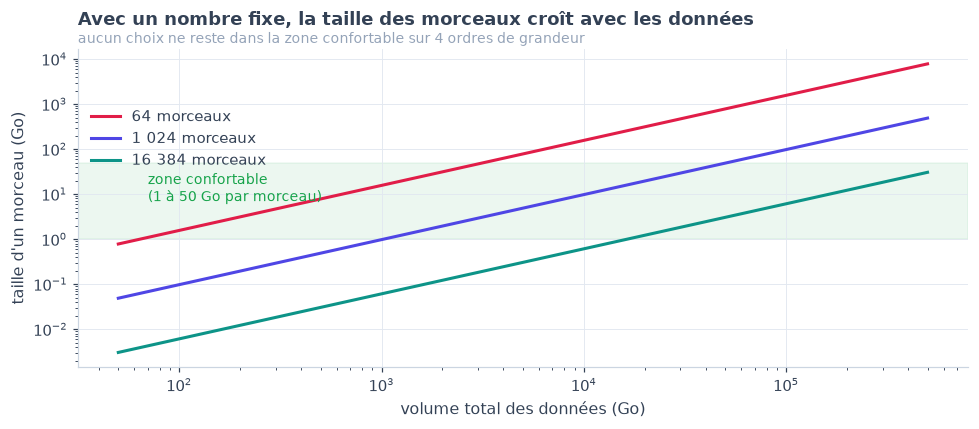

In [9]:
vol = np.logspace(np.log10(50), np.log10(500_000), 200)        # Go
fig, ax = plt.subplots(figsize=(9, 4))
for s, c in [(64, ROSE), (1024, INDIGO), (16384, TEAL)]:
    ax.plot(vol, vol / s, color=c, label=f"{fmt(s)} morceaux")
ax.axhspan(1, 50, color=GREEN, alpha=0.08)
ax.text(70, 7, "zone confortable\n(1 à 50 Go par morceau)", color=GREEN, fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("volume total des données (Go)"); ax.set_ylabel("taille d'un morceau (Go)")
ax.set_title("Avec un nombre fixe, la taille des morceaux croît avec les données")
subtitle(ax, "aucun choix ne reste dans la zone confortable sur 4 ordres de grandeur")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.85))
plt.tight_layout(); plt.show()

Si l'on s'est trompé, il faut **re-découper** (repartitionner) :
scinder chaque morceau en réécrivant toutes les données, opération lourde que certains
systèmes ne savent pas faire sans interruption.

> **À retenir.** Nombre fixe de morceaux : rééquilibrage optimal (on déplace des morceaux
> entiers, uniquement vers le nouveau nœud), machines hétérogènes faciles. Mais il faut
> deviner le bon nombre dès le départ : la taille des morceaux suit celle des données et le
> nombre de nœuds ne peut pas dépasser le nombre de morceaux.

## 4. Des partitions qui se scindent (section *Dynamic partitioning*)

**L'idée.** Laisser le nombre de morceaux **suivre le volume** : quand
une partition dépasse une taille limite (10 Go par défaut dans HBase),
on la coupe en deux à la clé médiane, comme un nœud de B-tree trop plein
(chapitre 3) ; les deux moitiés peuvent ensuite vivre sur des nœuds
différents. Inversement, des morceaux devenus trop petits après des suppressions
fusionnent. Cela s'applique au découpage par **plage de clés** (HBase, Bigtable,
RethinkDB, MongoDB) comme par **plage de hachés** (option de MongoDB) :
on découpe alors l'espace des hachés en intervalles contigus.

Insérons 200 000 clés avec une limite de 2 000 clés par morceau, et suivons le nombre de
morceaux et le coût des scissions (chaque scission **réécrit** tout le morceau, comme
une compaction).

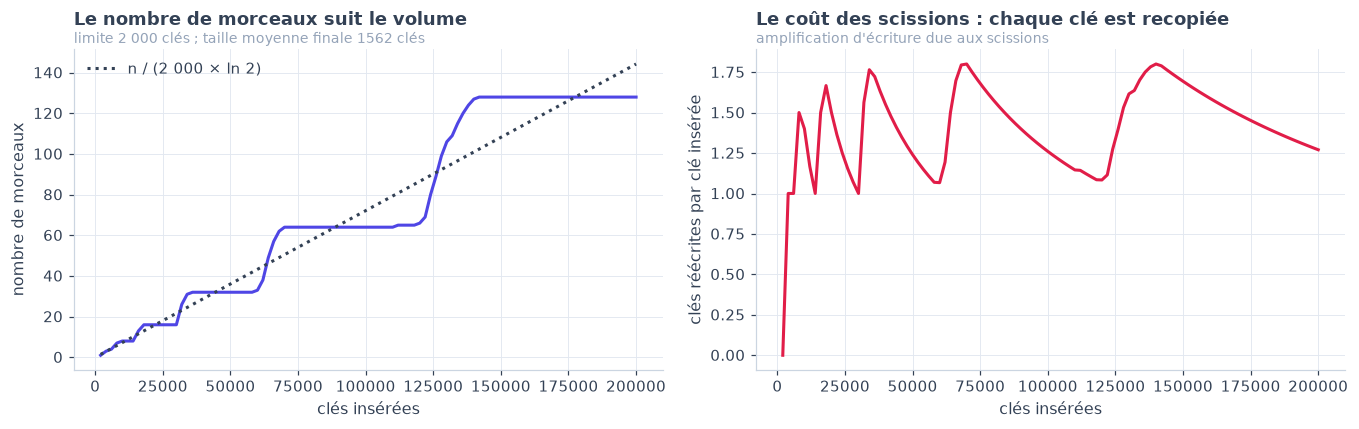

128 morceaux, tailles de 1399 à 1784 clés ; 1.27 réécriture par clé insérée


In [10]:
dyn = P.DynamicRangeSharding(max_keys=2_000, hashed=True)
order = rng.permutation(200_000)
trace = []
for i, k in enumerate(order, 1):
    dyn.insert(int(k))
    if i % 2_000 == 0:
        trace.append({"insérées": i, "morceaux": dyn.n_shards, "réécrites": dyn.rewritten})
trace = pd.DataFrame(trace)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
ax = axes[0]
ax.plot(trace["insérées"], trace["morceaux"], color=INDIGO)
ax.plot(trace["insérées"], trace["insérées"] / (2_000 * np.log(2)), ":", color=SLATE,
        label="n / (2 000 × ln 2)")
ax.set_xlabel("clés insérées"); ax.set_ylabel("nombre de morceaux")
ax.set_title("Le nombre de morceaux suit le volume")
subtitle(ax, f"limite 2 000 clés ; taille moyenne finale {200_000 / dyn.n_shards:.0f} clés")
ax.legend()
ax = axes[1]
ax.plot(trace["insérées"], trace["réécrites"] / trace["insérées"], color=ROSE)
ax.set_xlabel("clés insérées"); ax.set_ylabel("clés réécrites par clé insérée")
ax.set_title("Le coût des scissions : chaque clé est recopiée")
subtitle(ax, "amplification d'écriture due aux scissions")
plt.tight_layout(); plt.show()
print(f"{dyn.n_shards} morceaux, tailles de {dyn.sizes().min()} à {dyn.sizes().max()} clés ; "
      f"{dyn.rewritten / 200_000:.2f} réécriture par clé insérée")

Le nombre de morceaux progresse **par vagues** : les hachés étant uniformes, tous les
morceaux se remplissent au même rythme et se scindent presque en même temps (16, 32, 64,
puis 128 morceaux). Un morceau plein (2 000 clés) donne deux moitiés de 1 000 qui se
remplissent à leur tour : la taille moyenne oscille entre 1 000 et 2 000 clés, et vaut en
moyenne $2000 \ln 2 \approx 1\,390$ (un résultat classique des B-trees), d'où la droite
pointillée. L'amplification d'écriture due aux scissions oscille entre 1 et 1,8 réécriture
par clé insérée (1,27 à la fin) : un coût réel, et qui tombe au mauvais moment, car le
morceau à scinder est souvent **celui qui est déjà le plus chargé**.

**Le démarrage à froid et le pré-découpage.** Une base vide commence avec **un seul**
morceau : tant qu'il n'a pas atteint la limite, tout le trafic va sur un seul nœud. HBase
et MongoDB permettent donc de **pré-découper** (*pre-splitting*) une base vide, si l'on
connaît à l'avance la distribution des clés. Comparons la part des écritures reçue par le
morceau le plus sollicité, par tranches de 1 000 insertions, dans trois situations.

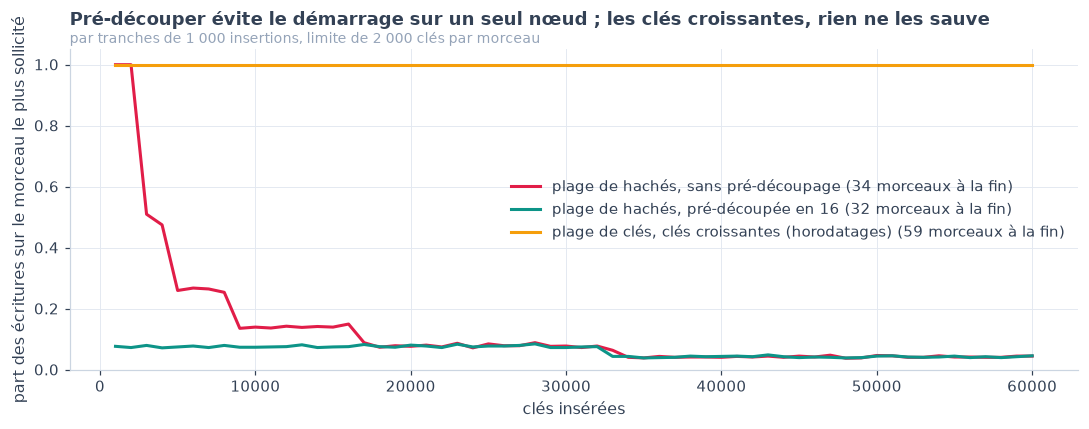

In [11]:
def busiest_share(sharding, keys, batch=1_000):
    out = []
    for b in range(0, len(keys), batch):
        sharding.reset_writes()
        for k in keys[b:b + batch]:
            sharding.insert(int(k))
        w = np.array(sharding.writes)
        out.append(w.max() / w.sum())
    return np.array(out)

keys60 = rng.permutation(1_000_000)[:60_000]
cases = {
    "plage de hachés, sans pré-découpage": (P.DynamicRangeSharding(2_000, hashed=True), keys60, ROSE),
    "plage de hachés, pré-découpée en 16": (P.DynamicRangeSharding(2_000, hashed=True, presplit=list(np.arange(1, 16) / 16)), keys60, TEAL),
    "plage de clés, clés croissantes (horodatages)": (P.DynamicRangeSharding(2_000), np.arange(60_000), AMBER),
}
fig, ax = plt.subplots(figsize=(10, 4))
for lab, (sh, ks, c) in cases.items():
    share = busiest_share(sh, ks)
    ax.plot(np.arange(1, len(share) + 1) * 1_000, share, color=c, label=f"{lab} ({sh.n_shards} morceaux à la fin)")
ax.set_xlabel("clés insérées"); ax.set_ylabel("part des écritures sur le morceau le plus sollicité")
ax.set_ylim(0, 1.05)
ax.set_title("Pré-découper évite le démarrage sur un seul nœud ; les clés croissantes, rien ne les sauve")
subtitle(ax, "par tranches de 1 000 insertions, limite de 2 000 clés par morceau")
ax.legend(loc="center right")
plt.tight_layout(); plt.show()

Sans pré-découpage, le premier morceau absorbe 100 % des écritures jusqu'à sa première
scission, puis la part du plus sollicité décroît à mesure que les morceaux se
multiplient. Pré-découpée, la base répartit dès la première écriture. Avec des clés
croissantes et un découpage par plage de clés, la scission ne sert à rien : la moitié
haute du dernier morceau reçoit à nouveau **toutes** les écritures (le point chaud du
cours 1, section 4) ; c'est pourquoi les systèmes à scission sur des plages de hachés
sont populaires.

> **À retenir.** Le partitionnement dynamique adapte le
> nombre de morceaux au volume (pas de nombre à deviner), au prix de scissions coûteuses
> qui réécrivent les données. Une base vide part d'un seul morceau, d'où l'intérêt du
> pré-découpage ; et des clés croissantes restent un point chaud.

## 5. Des plages aléatoires proportionnelles aux nœuds et le hachage cohérent (section *Partitioning proportionally to nodes*, *Consistent Hashing*)

**L'idée de Cassandra.** Une troisième voie : rendre le nombre de morceaux
**proportionnel au nombre de nœuds**. Chaque nœud tire au hasard quelques jetons
(*tokens*) sur l'anneau des hachés ; chaque jeton délimite une plage, qui va du jeton
précédent jusqu'à lui. Un nouveau nœud tire à son tour ses jetons : chacun **coupe** une
plage existante en deux et en récupère une moitié, sans que rien d'autre ne bouge.
Cassandra utilisait 256 jetons par nœud par défaut.

**Le hachage cohérent** désigne précisément un algorithme qui (1) répartit les clés à peu
près également entre les morceaux, et (2) en déplace le moins possible quand leur nombre
change. « Cohérent » n'a ici rien à voir avec la cohérence des répliques ni avec le C
d'ACID : il signifie qu'une clé tend à **rester** où elle est. L'anneau à jetons
aléatoires est la forme originelle de l'algorithme (Karger et al., 1997).

Dessinons un anneau de 3 nœuds à 4 jetons chacun, avant et après l'arrivée d'un 4e nœud.

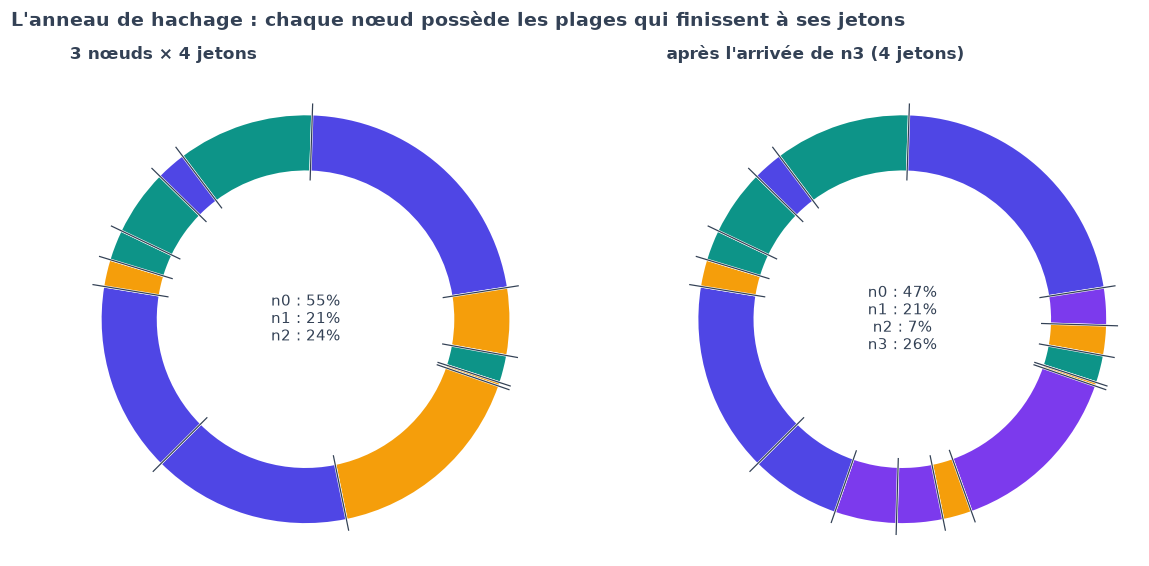

In [12]:
def draw_ring(ax, ring, title, colors):
    t = ring.tokens
    starts = np.concatenate([[t[-1] - 1], t[:-1]])
    for s, e, o in zip(starts, t, ring.token_owner):
        ax.add_patch(Wedge((0, 0), 1.0, 90 - e * 360, 90 - s * 360, width=0.28,
                           facecolor=colors[o], edgecolor="white", lw=1.5))
    for tok, o in zip(t, ring.token_owner):
        a = np.deg2rad(90 - tok * 360)
        ax.plot([0.68 * np.cos(a), 1.05 * np.cos(a)], [0.68 * np.sin(a), 1.05 * np.sin(a)], color=SLATE, lw=0.8)
    own = ring.ownership()
    txt = "\n".join(f"{o} : {own[o]:.0%}" for o in sorted(own))
    ax.text(0, 0, txt, ha="center", va="center", fontsize=9.5, color=SLATE)
    ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=11)

ring_colors = {"n0": INDIGO, "n1": TEAL, "n2": AMBER, "n3": VIOLET}
ring = P.HashRing(["n0", "n1", "n2"], vnodes=4, seed=7)
before_ring = P.HashRing(["n0", "n1", "n2"], vnodes=4, seed=7)
ring.add_node("n3")
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
draw_ring(axes[0], before_ring, "3 nœuds × 4 jetons", ring_colors)
draw_ring(axes[1], ring, "après l'arrivée de n3 (4 jetons)", ring_colors)
fig.suptitle("L'anneau de hachage : chaque nœud possède les plages qui finissent à ses jetons",
             x=0.01, ha="left", fontweight="bold", fontsize=12.5)
plt.tight_layout(); plt.show()

Les plages de n3 (violet) sont prises à ses voisins immédiats sur l'anneau ; toutes les
autres frontières restent en place. Avec si peu de jetons, la répartition est très
inégale (n0 possède 55 % de l'anneau avant l'ajout ; après, les parts vont de 7 % à
47 %, et n2 a presque tout cédé) : les frontières étant aléatoires, certaines plages sont
grandes et d'autres minuscules. **Plusieurs jetons par nœud** moyennent ces écarts.
Mesurons le déséquilibre (part du nœud le plus gros / part moyenne) sur 10 nœuds, selon
le nombre de jetons par nœud, et la fraction de clés déplacées en passant à 11 nœuds.

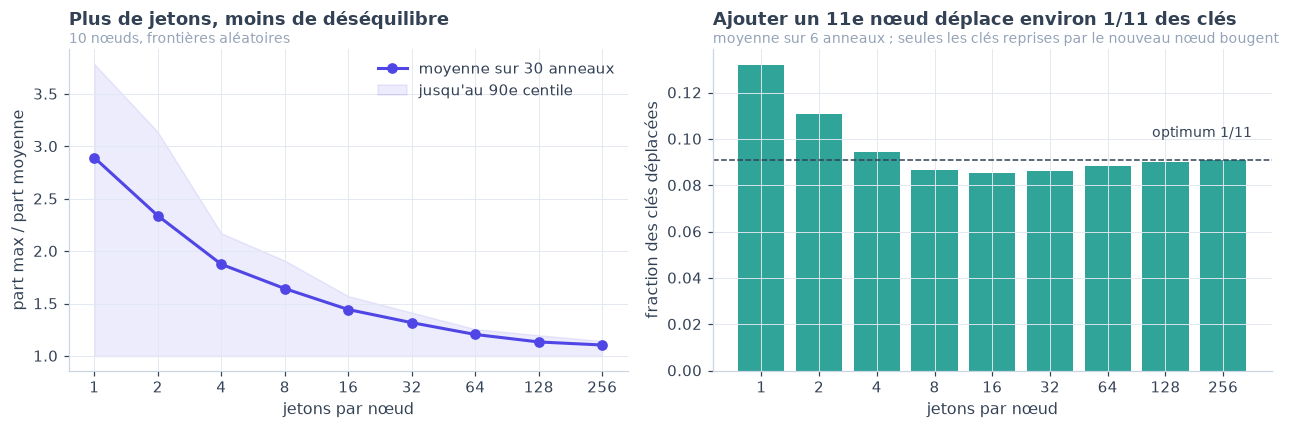

,jetons par nœud,déséquilibre moyen,déséquilibre p90,clés déplacées 10 → 11
0,1,2.893,3.786,0.132
1,2,2.339,3.138,0.111
2,4,1.876,2.171,0.094
3,8,1.644,1.910,0.087
4,16,1.444,1.571,0.085
5,32,1.318,1.414,0.086
6,64,1.206,1.257,0.088
7,128,1.134,1.198,0.090
8,256,1.105,1.143,0.091


In [13]:
vn_list = [1, 2, 4, 8, 16, 32, 64, 128, 256]
rows = []
for vn in vn_list:
    imb, mv = [], []
    for seed in range(30):
        r = P.HashRing([f"n{i}" for i in range(10)], vnodes=vn, seed=seed)
        imb.append(max(r.ownership().values()) * 10)
        if seed < 6:
            b = r.node_of(KEYS[:50_000]); r.add_node("n10"); a = r.node_of(KEYS[:50_000])
            mv.append(P.moved_fraction(b, a))
    rows.append({"jetons par nœud": vn, "déséquilibre moyen": np.mean(imb), "déséquilibre p90": np.quantile(imb, 0.9),
                 "clés déplacées 10 → 11": np.mean(mv)})
vn_tab = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
ax = axes[0]
ax.plot(vn_tab["jetons par nœud"], vn_tab["déséquilibre moyen"], "o-", color=INDIGO, label="moyenne sur 30 anneaux")
ax.fill_between(vn_tab["jetons par nœud"], 1, vn_tab["déséquilibre p90"], color=INDIGO, alpha=0.1, label="jusqu'au 90e centile")
ax.set_xscale("log", base=2); ax.set_xticks(vn_list); ax.set_xticklabels(vn_list)
ax.set_xlabel("jetons par nœud"); ax.set_ylabel("part max / part moyenne")
ax.set_title("Plus de jetons, moins de déséquilibre")
subtitle(ax, "10 nœuds, frontières aléatoires")
ax.legend()
ax = axes[1]
ax.bar(range(len(vn_list)), vn_tab["clés déplacées 10 → 11"], color=TEAL, alpha=0.85)
ax.axhline(1 / 11, color=SLATE, ls="--", lw=1); ax.text(len(vn_list) - 0.5, 1 / 11 + 0.01, "optimum 1/11", ha="right", fontsize=9)
ax.set_xticks(range(len(vn_list))); ax.set_xticklabels(vn_list)
ax.set_xlabel("jetons par nœud"); ax.set_ylabel("fraction des clés déplacées")
ax.set_title("Ajouter un 11e nœud déplace environ 1/11 des clés")
subtitle(ax, "moyenne sur 6 anneaux ; seules les clés reprises par le nouveau nœud bougent")
plt.tight_layout(); plt.show()
vn_tab.round(3)

Avec un seul jeton, le nœud le plus gros possède en moyenne près de trois fois sa part ;
avec 256 jetons, l'écart tombe à quelques pour cent (il décroît comme
$1/\sqrt{\text{jetons}}$, comme l'écart-type d'une moyenne). La fraction déplacée reste
proche de l'optimum 1/11 en moyenne, mais avec peu de jetons elle dépend du hasard : le
nouveau nœud récupère ce que ses jetons découpent.

**À qui le nouveau nœud prend-il ?** Avec un seul jeton, il prend tout à **un seul**
voisin ; avec beaucoup de jetons, il prend un peu à **chacun**, ce qui répartit l'effort
du transfert (et la perte de charge) sur tout le cluster.

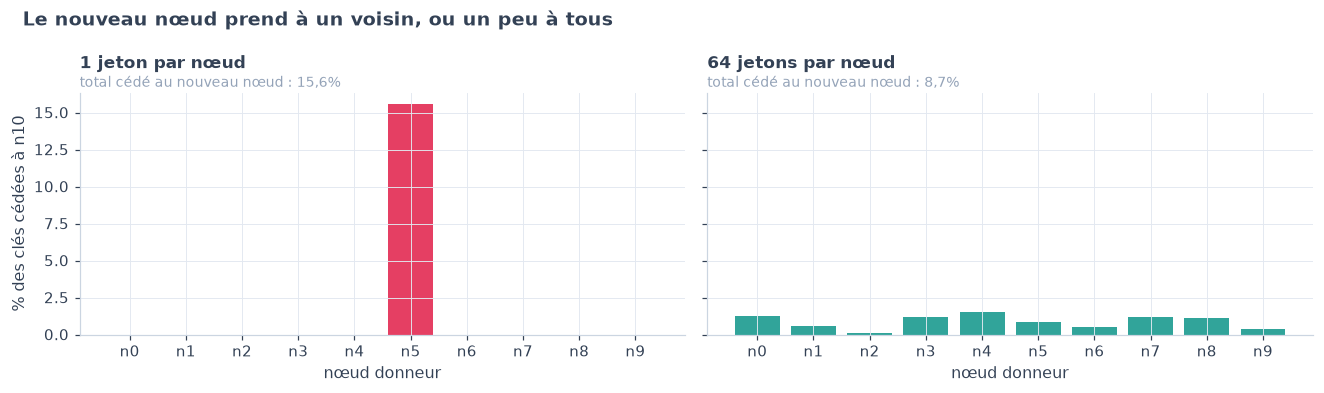

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, vn in zip(axes, [1, 64]):
    r = P.HashRing([f"n{i}" for i in range(10)], vnodes=vn, seed=3)
    b = r.node_of(KEYS); r.add_node("n10"); a = r.node_of(KEYS)
    donors = pd.Series(b[(a == "n10")]).value_counts().reindex([f"n{i}" for i in range(10)], fill_value=0) / KEYS.size
    ax.bar(donors.index, donors.values * 100, color=ROSE if vn == 1 else TEAL, alpha=0.85)
    ax.set_title(f"{vn} jeton{'s' if vn > 1 else ''} par nœud", fontsize=11)
    ax.set_xlabel("nœud donneur")
    subtitle(ax, f"total cédé au nouveau nœud : {donors.sum():.1%}".replace(".", ","))
axes[0].set_ylabel("% des clés cédées à n10")
fig.suptitle("Le nouveau nœud prend à un voisin, ou un peu à tous", x=0.01, ha="left", fontweight="bold", fontsize=12.5)
plt.tight_layout(); plt.show()

> **À retenir.** Des plages aléatoires proportionnelles aux nœuds (Cassandra) forment un
> **hachage cohérent** : équilibre approximatif, et un ajout de nœud ne déplace que les clés
> qu'il récupère. Il faut **beaucoup de jetons par nœud** pour lisser le hasard des
> frontières et répartir l'effort du transfert.